# 01 - Data understanding and cleaning (H2, City Hotel)
Cells run top to bottom. Cell 1-2 are the setup / raw inspection; cells 3-6 apply the two cleaning layers
from `src/preprocessing/cleaning.py`, driven by `config/datasets/h2.yaml`.

In [1]:
# Cell 1 - setup and paths
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

RANDOM_STATE = 42  # Fixed seed (spec: use fixed random seeds where applicable).
np.random.seed(RANDOM_STATE)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 140)
sns.set_theme(style='whitegrid', context='notebook')

# Resolve the project root when launched either at the project root or in notebooks/.
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'data' / 'H2.csv').is_file():
    PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / 'data' / 'H2.csv'
if not DATA_PATH.is_file():
    raise FileNotFoundError(f'Expected the project dataset at {DATA_PATH}')

OUTPUT_FIGURES = PROJECT_ROOT / 'outputs' / 'figures'
OUTPUT_TABLES = PROJECT_ROOT / 'outputs' / 'tables'
OUTPUT_FIGURES.mkdir(parents=True, exist_ok=True)
OUTPUT_TABLES.mkdir(parents=True, exist_ok=True)

# Make `src` importable from a notebook that lives in notebooks/.
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [2]:
# Cell 2 - load and inspect the RAW data (never modified below)
df = pd.read_csv(DATA_PATH)
print(f'Dataset: {DATA_PATH}')
print(f'Shape: {df.shape[0]:,} rows x {df.shape[1]} columns')
display(df.head())

print('Column names:')
print(df.columns.tolist())

print('\nData types:')
display(df.dtypes.rename('dtype').to_frame())

print('\nDataFrame info:')
df.info()

Dataset: /Users/mohamedatef/ML Project/Hotel_Booking_ML-/data/H2.csv
Shape: 79,330 rows x 31 columns


,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateMonth,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,Babies,Meal,Country,MarketSegment,DistributionChannel,IsRepeatedGuest,PreviousCancellations,PreviousBookingsNotCanceled,ReservedRoomType,AssignedRoomType,BookingChanges,DepositType,Agent,Company,DaysInWaitingList,CustomerType,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests,ReservationStatus,ReservationStatusDate
0,0,6,2015,July,27,1,0,2,1,0.0,0,HB,PRT,Offline TA/TO,TA/TO,0,0,0,A,A,0,No Deposit,6,NULL,0,Transient,0.0,0,0,Check-Out,2015-07-03
1,1,88,2015,July,27,1,0,4,2,0.0,0,BB,PRT,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9,NULL,0,Transient,76.5,0,1,Canceled,2015-07-01
2,1,65,2015,July,27,1,0,4,1,0.0,0,BB,PRT,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9,NULL,0,Transient,68.0,0,1,Canceled,2015-04-30
3,1,92,2015,July,27,1,2,4,2,0.0,0,BB,PRT,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9,NULL,0,Transient,76.5,0,2,Canceled,2015-06-23
4,1,100,2015,July,27,2,0,2,2,0.0,0,BB,PRT,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9,NULL,0,Transient,76.5,0,1,Canceled,2015-04-02


Column names:
['IsCanceled', 'LeadTime', 'ArrivalDateYear', 'ArrivalDateMonth', 'ArrivalDateWeekNumber', 'ArrivalDateDayOfMonth', 'StaysInWeekendNights', 'StaysInWeekNights', 'Adults', 'Children', 'Babies', 'Meal', 'Country', 'MarketSegment', 'DistributionChannel', 'IsRepeatedGuest', 'PreviousCancellations', 'PreviousBookingsNotCanceled', 'ReservedRoomType', 'AssignedRoomType', 'BookingChanges', 'DepositType', 'Agent', 'Company', 'DaysInWaitingList', 'CustomerType', 'ADR', 'RequiredCarParkingSpaces', 'TotalOfSpecialRequests', 'ReservationStatus', 'ReservationStatusDate']

Data types:


,dtype
IsCanceled,int64
LeadTime,int64
ArrivalDateYear,int64
ArrivalDateMonth,object
ArrivalDateWeekNumber,int64
ArrivalDateDayOfMonth,int64
StaysInWeekendNights,int64
StaysInWeekNights,int64
Adults,int64
Children,float64



DataFrame info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 79330 entries, 0 to 79329
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   IsCanceled                   79330 non-null  int64  
 1   LeadTime                     79330 non-null  int64  
 2   ArrivalDateYear              79330 non-null  int64  
 3   ArrivalDateMonth             79330 non-null  object 
 4   ArrivalDateWeekNumber        79330 non-null  int64  
 5   ArrivalDateDayOfMonth        79330 non-null  int64  
 6   StaysInWeekendNights         79330 non-null  int64  
 7   StaysInWeekNights            79330 non-null  int64  
 8   Adults                       79330 non-null  int64  
 9   Children                     79326 non-null  float64
 10  Babies                       79330 non-null  int64  
 11  Meal                         79330 non-null  object 
 12  Country                      79306 non-null  object 
 13 

## Cleaning - Layer 1 (generic)
Trim whitespace, standardise missing markers, drop duplicates. Cell 3 first *measures* the problems on the raw data
so the report can quote them.

In [3]:
# Cell 3 - quantify the problems BEFORE cleaning
from src.preprocessing.cleaning import trim_whitespace, standardize_missing, remove_duplicates

text_cols = df.select_dtypes(exclude='number').columns
padded = {c: int((df[c].dropna() != df[c].dropna().str.strip()).sum()) for c in text_cols}
padded = {c: n for c, n in padded.items() if n}

before = pd.DataFrame({
    'padded_values': pd.Series(padded),
    'null_strings': pd.Series({c: int(df[c].astype(str).str.strip().str.upper().eq('NULL').sum())
                               for c in text_cols}),
    'real_NaN': df.isna().sum(),
}).fillna(0).astype(int)
before = before[(before > 0).any(axis=1)]
display(before)
print(f'Exact duplicate rows: {df.duplicated().sum():,} ({df.duplicated().mean():.1%})')
before.to_csv(OUTPUT_TABLES / 'raw_data_quality.csv')

,padded_values,null_strings,real_NaN
Agent,79330,8131,0
AssignedRoomType,79330,0,0
Children,0,0,4
Company,79330,75641,0
Country,0,0,24
DepositType,79330,0,0
Meal,79330,0,0
ReservedRoomType,79330,0,0


Exact duplicate rows: 25,902 (32.7%)


In [4]:
# Cell 4 - apply Layer 1 step by step (each helper returns a new frame)
step1 = trim_whitespace(df)
step2 = standardize_missing(step1)
step3 = remove_duplicates(step2)
n_dup = len(step2) - len(step3)
print(f'rows: {len(df):,} -> {len(step3):,}   missing cells: {int(df.isna().sum().sum()):,} -> {int(step3.isna().sum().sum()):,}')
print(f'Duplicate rows removed: {n_dup:,} ({n_dup / len(df):.1%} of the raw rows)')

rows: 79,330 -> 53,428   missing cells: 28 -> 56,243
Duplicate rows removed: 25,902 (32.7% of the raw rows)


**Why dropping exact duplicates is acceptable (write this in the report).**
The PMS export has no booking-ID column, so two identical rows could in theory be two different bookings
(for example two identical rooms booked together by the same agency). We drop them anyway because:
(1) with 30+ columns including dates, lead time, agent, ADR and room type, a coincidental exact match is rare;
(2) keeping copies would put the same booking in both train and test, which inflates the test score (indirect leakage);
(3) the share removed is reported above, so the effect is transparent. This is a documented assumption, not a certainty.

## Cleaning - Layer 2 (dataset-specific)
`config/datasets/h2.yaml` decides which rules run (Undefined -> NaN, type casting, ADR limits, invalid guest counts).
Running the orchestrator applies **both** layers from the original `df` and writes the cleaned CSV + report.

In [5]:
# Cell 5 - run both layers through the description file
import json
from src.preprocessing.cleaning import clean_from_description

df_clean, cleaning_report = clean_from_description(
    'config/datasets/h2.yaml', project_root=PROJECT_ROOT, df=df, save=True)
print(json.dumps(cleaning_report, indent=2))
print(f'Cleaned shape: {df_clean.shape[0]:,} rows x {df_clean.shape[1]} columns')

{
  "dataset": "H2 City Hotel",
  "generic": {
    "rows_in": 79330,
    "missing_markers_converted": 83772,
    "duplicates_removed": 25902,
    "rows_out": 53428
  },
  "dataset_rules": [
    {
      "rule": "adr_outliers",
      "rows_removed": 1
    },
    {
      "rule": "invalid_guest_count",
      "rows_removed": 154
    },
    {
      "rule": "zero_night_stays",
      "rows_removed": 231
    }
  ],
  "final_rows": 53042
}
Cleaned shape: 53,042 rows x 31 columns


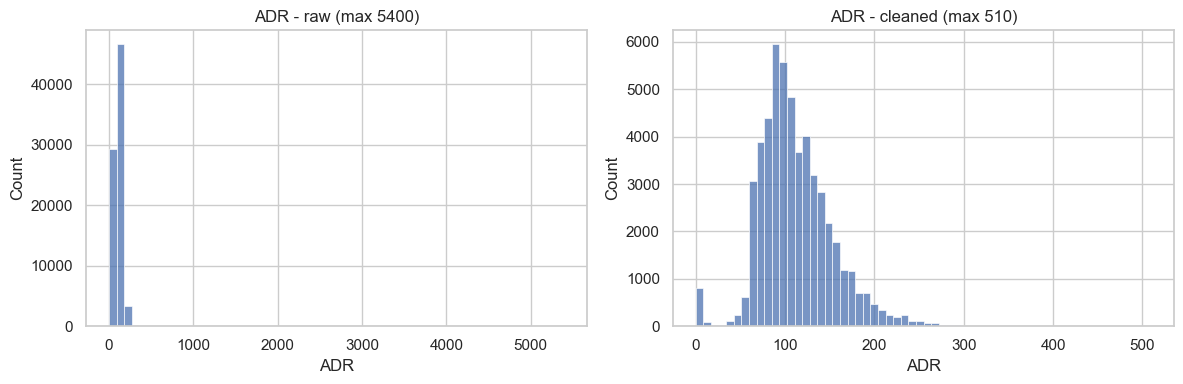

,missing_after_cleaning
Children,4
Country,3
Agent,5471
Company,50300



Agent / Company dtypes after cleaning:
Agent      object
Company    object
dtype: object


In [6]:
# Cell 6 - sanity checks and before/after ADR figure
assert df_clean.duplicated().sum() == 0, 'duplicates remain'
assert df_clean['ADR'].notna().all(), 'ADR contains NaN after cleaning'
assert df_clean['ADR'].between(0, 1000).all(), 'ADR outside the allowed 0-1000 range'
assert len(df) == 79_330, 'raw df was modified'

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['ADR'], bins=60, ax=axes[0]); axes[0].set_title('ADR - raw (max {:.0f})'.format(df['ADR'].max()))
sns.histplot(df_clean['ADR'], bins=60, ax=axes[1]); axes[1].set_title('ADR - cleaned (max {:.0f})'.format(df_clean['ADR'].max()))
plt.tight_layout()
fig.savefig(OUTPUT_FIGURES / 'adr_before_after_cleaning.png', dpi=150)
plt.show()

display(df_clean.isna().sum().loc[lambda s: s > 0].rename('missing_after_cleaning').to_frame())

# Agent / Company are IDs: check what dtype cleaning gave them (notebook 02 handles either case)
print('\nAgent / Company dtypes after cleaning:')
print(df_clean[[c for c in ['Agent', 'Company'] if c in df_clean.columns]].dtypes)